# Scotland in depth: Yes 2014 and Remain 2016

**Project:** Why Britain voted Leave, and where the explanation breaks

**Why this notebook:** notebooks 01 and 02 showed that demographics **overestimate Leave in Scotland by about 15 points**. Scotland is where the explanation breaks. This notebook looks at Scotland's 32 councils in depth, using two referendums:

- **18 September 2014:** "Should Scotland be an independent country?" (Yes / No)
- **23 June 2016:** "Should the UK remain a member of the EU?" (Remain / Leave)

**Questions**

1. How did each council vote in 2014, and where were the Yes areas? (maps)
2. Are the Yes map and the Remain map the same map?
3. Which characteristics go with Yes, and which go with Remain?
4. How did turnout change between the two votes, and where?
5. What do the city breakdowns and polling-day surveys add?

**New data in this notebook:** `scotland_rp1450_indicators.csv`, extracted from House of Commons Library **Research Paper 14/50** (30 September 2014):
- Table 3.1: SNP share at the 2014 European election, "Scottish only" national identity and born in Scotland (2011 Census), the out-of-work benefit rate (Feb 2014) and the 65+ share (2013).
- Table 1: registered 16-17-year-old voters.

Small tables from the paper (Glasgow and Edinburgh constituencies, polling-day surveys) are typed directly into the cells that use them, with their source.

**Remember:** with only **32 councils**, a single council can move a correlation a lot. All results describe **councils, not individual voters**.

## Key terms in simple words

| Term | Meaning |
|---|---|
| **Council** | One of Scotland's 32 local authorities. Both referendums were counted by council, so they are our units. |
| **Yes share** | Yes votes as a share of valid votes in 2014. |
| **Remain share** | Remain votes as a share of valid votes in 2016. |
| **Turnout** | Votes cast as a share of the electorate. |
| **Turnout drop** | Turnout in 2014 minus turnout in 2016, in percentage points. |
| **SNP Euro 2014** | The SNP's share of the vote at the May 2014 European election, four months before the independence vote. |
| **Scottish-only identity** | The share of residents who described their national identity as "Scottish only" in the 2011 Census, rather than "Scottish and British", "British only" or other. |
| **Out-of-work benefit rate** | The share of people aged 16-64 claiming JSA, Income Support or an incapacity benefit (Feb 2014). It is broader than the claimant rate, which counts JSA only. |
| **Rank** | 1 = the council with the highest share. |
| **Change option** | The option that would change the status quo: Yes in 2014, Leave in 2016. |

**Colours:** as in notebook 01, **orange = the change option** (Yes, Leave), **blue = the status quo** (No, Remain), and the palest colour is 50%. So the 2014 and 2016 maps use the same logic.

## 1. Setup

Same libraries, style and colours as notebooks 01 and 02.

In [12]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, Normalize
from matplotlib.patches import Rectangle
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SCOTLAND = "#2a78d6"   # blue: status quo (No, Remain)
LONDON = "#eb6834"     # orange: change option (Yes, Leave)
OTHER = "#b5b3ac"
PURPLE = "#4a3f9f"

# Blue for the status quo, pale at 50%, orange for the change option
vote_colours = LinearSegmentedColormap.from_list("vote", [SCOTLAND, "#ece9e2", LONDON])
# Scotland's shares sit between about 30% and 70%, so we use a tighter scale than the GB map (25-75%)
vote_scale = TwoSlopeNorm(vmin=30, vcenter=50, vmax=70)
purple_colours = LinearSegmentedColormap.from_list("purple", ["#e6e4f3", PURPLE])

## 2. Load and join the data

**What this cell does**

1. It loads the Scotland table from notebook 01 (both referendums, plus census and economic measures).
2. It loads the new indicators from Research Paper 14/50 and joins them on the **council code**.
3. It loads the 2016 vote counts for Scotland from the Great Britain table, so we can add up votes for the whole of Scotland.
4. It loads the boundaries and keeps only the Scottish shapes (codes starting with S).
5. It checks that we have all 32 councils in every table.

In [13]:
DATA_DIR = Path("../data")  # the data folder of this repository

scotland = pd.read_csv(DATA_DIR / "scotland_2014_2016.csv")
rp = pd.read_csv(DATA_DIR / "scotland_rp1450_indicators.csv")
areas = pd.read_csv(DATA_DIR / "gb_areas_clean.csv")
with open(DATA_DIR / "gb_areas_boundaries.geojson") as f:
    boundaries = json.load(f)

# Join the new indicators by council code; validate checks one row per council on each side
sc = scotland.merge(rp, on=["code", "area"], how="inner", validate="1:1")
votes16 = areas[areas["nation"] == "Scotland"][["code", "electorate", "votes_cast", "valid_votes",
                                                "remain_votes", "leave_votes"]]
sc = sc.merge(votes16, on="code", validate="1:1")

# Extra columns used below
sc["no_pct"] = 100 - sc["yes_pct"]
sc["turnout_drop"] = sc["turnout_2014_pct"] - sc["turnout_pct"]
sc["yes_rank"] = sc["yes_pct"].rank(ascending=False).astype(int)
sc["remain_rank"] = sc["remain_pct"].rank(ascending=False).astype(int)

# Scottish shapes only
features = [f for f in boundaries["features"] if f["properties"]["code"].startswith("S")]

print("Councils after joining:", len(sc))
print("Scottish shapes in the boundary file:", len(features))
print("Missing values:", int(sc.isna().sum().sum()))
display(sc[["area", "yes_pct", "remain_pct", "turnout_2014_pct", "turnout_pct",
            "snp_euro_2014_pct", "scottish_only_identity_pct"]].head().round(1))

Councils after joining: 32
Scottish shapes in the boundary file: 32
Missing values: 0


,area,yes_pct,remain_pct,turnout_2014_pct,turnout_pct,snp_euro_2014_pct,scottish_only_identity_pct
0,Aberdeen City,41.4,61.1,81.7,67.9,29.6,54.7
1,Aberdeenshire,39.6,55.0,87.2,70.6,31.3,61.3
2,Angus,43.7,55.3,85.7,68.0,37.8,66.8
3,Argyll and Bute,41.5,60.6,88.2,73.1,28.4,57.4
4,City of Edinburgh,38.9,74.4,84.4,73.0,23.1,48.8


## 3. The big picture: two referendums, two years apart

**What this cell does:** it adds up the votes for all 32 councils. Adding votes (rather than averaging council percentages) gives big councils like Glasgow their real weight.

,2014 independence,2016 EU
change option,Yes,Leave
change votes,1617989,1018322
status quo votes,2001926,1661191
change share %,44.696878,38.003996
councils won by change,4,0
turnout %,84.499706,67.246142


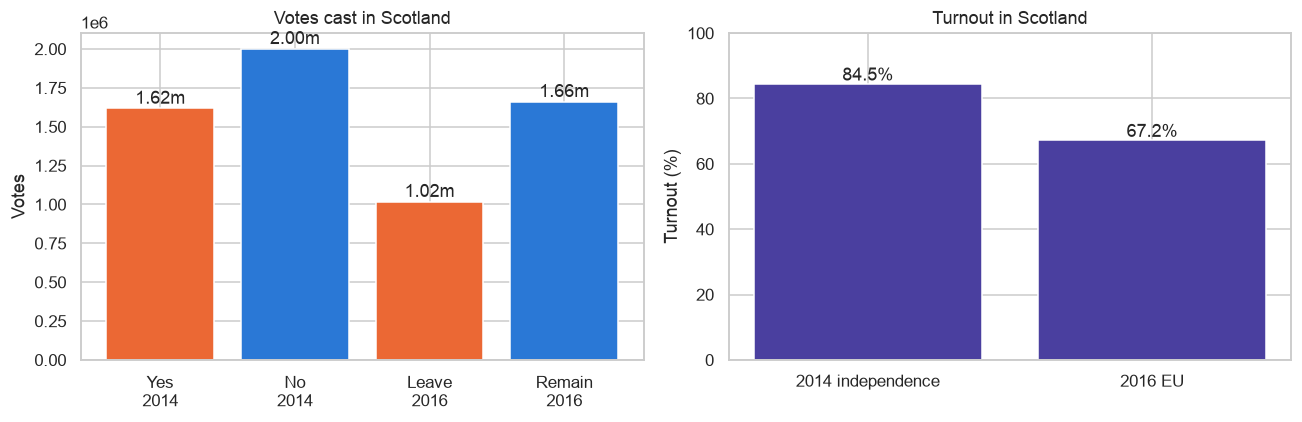

In [14]:
yes, no = sc["yes_votes"].sum(), sc["no_votes"].sum()
remain, leave = sc["remain_votes"].sum(), sc["leave_votes"].sum()
turnout14 = 100 * (sc["yes_votes"] + sc["no_votes"]).sum() / sc["electorate_2014"].sum()
turnout16 = 100 * sc["votes_cast"].sum() / sc["electorate"].sum()

summary = pd.DataFrame({
    "2014 independence": {"change option": "Yes", "change votes": yes, "status quo votes": no,
                          "change share %": 100 * yes / (yes + no), "councils won by change": (sc["yes_pct"] > 50).sum(),
                          "turnout %": turnout14},
    "2016 EU": {"change option": "Leave", "change votes": leave, "status quo votes": remain,
                "change share %": 100 * leave / (leave + remain), "councils won by change": (sc["leave_pct"] > 50).sum(),
                "turnout %": turnout16}})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["Yes\n2014", "No\n2014", "Leave\n2016", "Remain\n2016"], [yes, no, leave, remain],
            color=[LONDON, SCOTLAND, LONDON, SCOTLAND])
for i, v in enumerate([yes, no, leave, remain]):
    axes[0].text(i, v + 30000, f"{v / 1e6:.2f}m", ha="center")
axes[0].set_ylabel("Votes")
axes[0].set_title("Votes cast in Scotland")
axes[1].bar(["2014 independence", "2016 EU"], [turnout14, turnout16], color=PURPLE)
for i, v in enumerate([turnout14, turnout16]):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Turnout (%)")
axes[1].set_title("Turnout in Scotland")
plt.tight_layout()
plt.show()

**What we see**

- **2014:** Yes won **44.7%** (1.62 million votes) and won **4 of 32 councils**. Turnout was **84.5%** counting valid votes (84.6% with rejected papers, the official figure): the highest in Scotland since 1918, according to RP14/50.
- **2016:** Leave won only **38.0%** in Scotland (1.02 million votes) and **no council**. Turnout fell to **67.2%**.
- **Remain got more votes (1.66 million) than Yes (1.62 million)**, even with about 940,000 fewer votes cast in total.
- So about **1 million people who voted in 2014 didn't vote in 2016**, after allowing for changes to the electorate. 16-17-year-olds could vote in 2014 but not in 2016, which explains part of the gap (109,533 registered).

## 4. Map: the Yes vote by council

This works like the London map in notebook 01:

1. Each council is coloured by its Yes share: **orange = Yes**, **blue = No**, pale = close to 50%.
2. Each council gets its **rank number** (1 = highest Yes). The ranked list on the right gives the name and value for each number.
3. The **Central Belt** (Glasgow, Edinburgh and the councils between them) holds half of Scotland's voters but is tiny on the map, so we show it zoomed in. The black box on the main map marks the zoomed area.

**What the helper functions do**

- `shapes_for()` turns the boundary file into a list of outlines, with the council code for each one. Island councils have many shapes.
- `label_point()` finds the centre of each council's largest shape, to place its number.
- `draw_scotland()` draws the outlines coloured by a value. We use it for every map in this notebook.

In [15]:
def outer_rings(geometry):
    polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    return [np.asarray(p[0]) for p in polygons]


def ring_area_centre(ring):
    # Area and centre of one outline (shoelace formula)
    x, y = ring[:, 0], ring[:, 1]
    cross = x[:-1] * y[1:] - x[1:] * y[:-1]
    a = cross.sum() / 2
    if a == 0:
        return 0, ring.mean(axis=0)
    return abs(a), np.array([((x[:-1] + x[1:]) * cross).sum() / (6 * a), ((y[:-1] + y[1:]) * cross).sum() / (6 * a)])


def shapes_for(features):
    shapes, codes = [], []
    for f in features:
        for ring in outer_rings(f["geometry"]):
            shapes.append(ring)
            codes.append(f["properties"]["code"])
    return shapes, codes


def label_point(feature):
    return max((ring_area_centre(r) for r in outer_rings(feature["geometry"])), key=lambda t: t[0])[1]


SHAPES, SHAPE_CODES = shapes_for(features)
LABEL_AT = {f["properties"]["code"]: label_point(f) for f in features}
SCOTLAND_BOX = (-7.7, -0.7, 54.6, 60.9)     # lon min, lon max, lat min, lat max
CENTRAL_BELT = (-4.95, -2.85, 55.55, 56.25)


def draw_scotland(ax, values, cmap=vote_colours, norm=vote_scale, box=SCOTLAND_BOX, edge=0.3):
    # values: a Series indexed by council code
    layer = PolyCollection(SHAPES, array=np.array([values[c] for c in SHAPE_CODES]), cmap=cmap, norm=norm,
                           edgecolors="white", linewidths=edge)
    ax.add_collection(layer)
    ax.set_xlim(box[0], box[1])
    ax.set_ylim(box[2], box[3])
    ax.set_aspect(1.75)        # same shape correction as notebook 01
    ax.set_axis_off()
    return layer


def in_box(point, box):
    return box[0] <= point[0] <= box[1] and box[2] <= point[1] <= box[3]

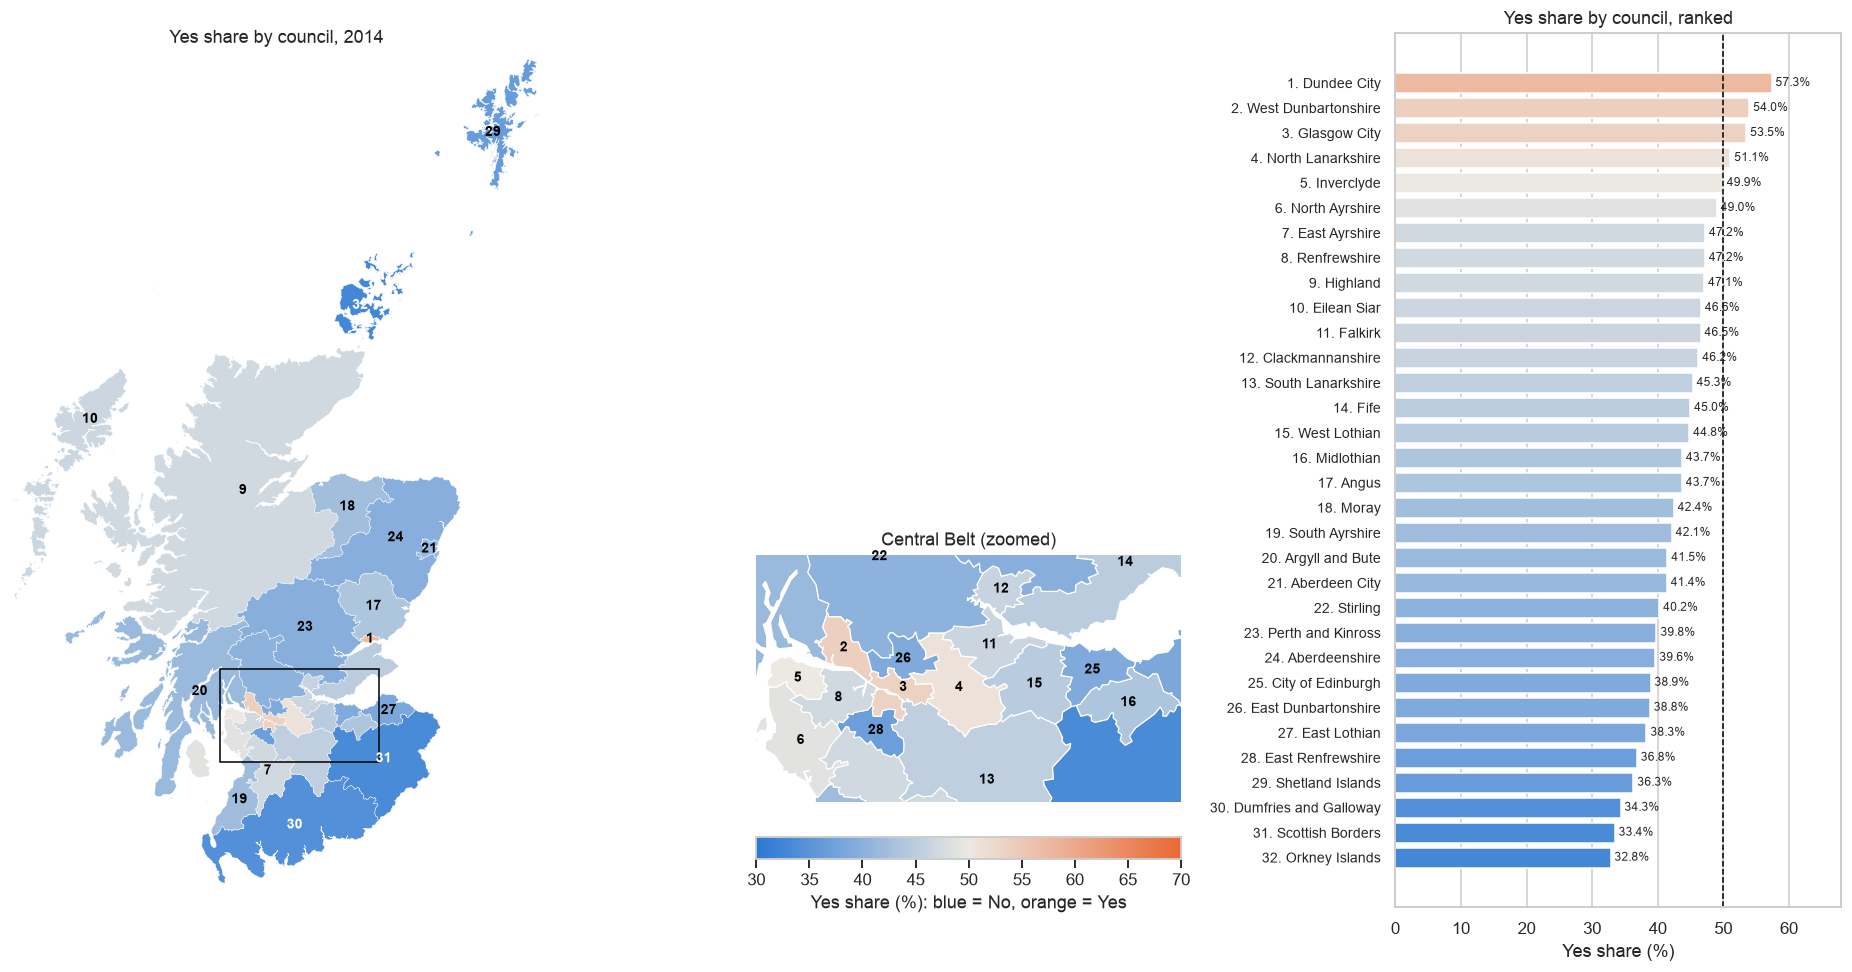

In [16]:
yes_by_code = sc.set_index("code")["yes_pct"]
ranked = sc.sort_values("yes_rank")

fig, (map_ax, zoom_ax, bar_ax) = plt.subplots(1, 3, figsize=(17, 9), gridspec_kw={"width_ratios": [1.25, 1, 1.05]})

# Main map and Central Belt zoom
layer = draw_scotland(map_ax, yes_by_code)
draw_scotland(zoom_ax, yes_by_code, box=CENTRAL_BELT, edge=0.8)
map_ax.add_patch(Rectangle((CENTRAL_BELT[0], CENTRAL_BELT[2]), CENTRAL_BELT[1] - CENTRAL_BELT[0],
                           CENTRAL_BELT[3] - CENTRAL_BELT[2], fill=False, edgecolor="black", linewidth=1))
map_ax.set_title("Yes share by council, 2014")
zoom_ax.set_title("Central Belt (zoomed)")

# Rank numbers: councils centred in the box are numbered on the zoom, the others on the main map
for _, row in sc.iterrows():
    x, y = LABEL_AT[row["code"]]
    target = zoom_ax if in_box((x, y), CENTRAL_BELT) else map_ax
    colour = "white" if row["yes_pct"] < 35 else "black"
    target.text(x, y, str(row["yes_rank"]), ha="center", va="center", fontsize=9, fontweight="bold", color=colour)

# Ranked list
bar_ax.barh(ranked["yes_rank"], ranked["yes_pct"], color=vote_colours(vote_scale(ranked["yes_pct"])))
bar_ax.set_yticks(ranked["yes_rank"], [f'{r}. {a}' for r, a in zip(ranked["yes_rank"], ranked["area"])], fontsize=9)
bar_ax.invert_yaxis()
bar_ax.axvline(50, color="black", linestyle="--", linewidth=1)
for _, row in ranked.iterrows():
    bar_ax.text(row["yes_pct"] + 0.6, row["yes_rank"], f'{row["yes_pct"]:.1f}%', va="center", fontsize=8)
bar_ax.set_xlim(0, 68)
bar_ax.set_xlabel("Yes share (%)")
bar_ax.set_title("Yes share by council, ranked")
bar_ax.grid(axis="y", visible=False)

# Colour key under the zoomed map
fig.colorbar(layer, ax=zoom_ax, orientation="horizontal", fraction=0.08, pad=0.04,
             label="Yes share (%): blue = No, orange = Yes")
plt.tight_layout()
plt.show()

**What we see**

- **Yes won only four councils, all in the west-central industrial belt:** Dundee (57.3%), West Dunbartonshire (54.0%), Glasgow (53.5%) and North Lanarkshire (51.1%). Inverclyde (49.9%) missed by 86 votes.
- **The strongest No areas are at the edges:** Orkney (32.8% Yes), the Scottish Borders (33.4%), Dumfries and Galloway (34.3%) and Shetland (36.3%). These are the councils bordering England, and the northern isles.
- **The wealthy Glasgow and Edinburgh suburbs** voted firmly No: East Renfrewshire (36.8%), East Dunbartonshire (38.8%) and Edinburgh (38.9%). Look at the zoom: Glasgow is orange, its wealthy suburbs on both sides are blue.
- **The Highlands and Western Isles** came closer to 50% than most rural areas (47.1% and 46.6%).

## 5. Same country, two maps: Yes 2014 and Leave 2016

**What this cell does:** it draws the 2014 and 2016 votes side by side, with **the same colours and the same scale**. Orange is always the change option (Yes, Leave), blue the status quo (No, Remain). If the two votes followed the same logic, the two maps would look alike.

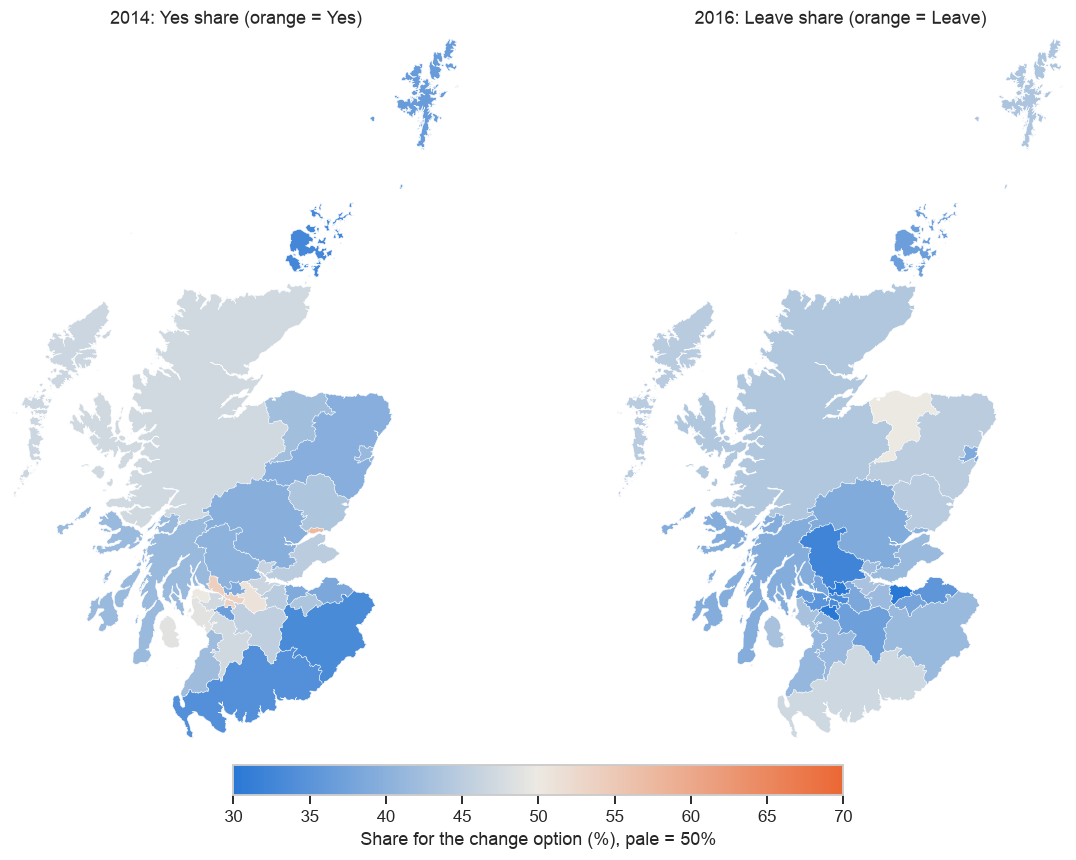

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
layer = draw_scotland(axes[0], sc.set_index("code")["yes_pct"])
draw_scotland(axes[1], sc.set_index("code")["leave_pct"])
axes[0].set_title("2014: Yes share (orange = Yes)")
axes[1].set_title("2016: Leave share (orange = Leave)")
fig.colorbar(layer, ax=axes, orientation="horizontal", fraction=0.04, pad=0.03,
             label="Share for the change option (%), pale = 50%")
plt.show()

**What we see**

- **2014** shows a clear geography: orange in the west-central belt and Dundee, blue at the edges.
- **2016** is **blue everywhere**: every council voted Remain. Moray came closest to Leave (49.9%), followed by Dumfries and Galloway (46.9%), Aberdeenshire (45.0%) and Eilean Siar (44.8%).
- **The orange areas of 2014 aren't the palest areas of 2016.** Glasgow was strongly Yes and strongly Remain. Moray and the north-east were mostly No and the least Remain.

The next sections measure how different the two maps really are.

## 6. Are Yes and Remain the same vote?

### 6.1 Scatter plot

**What this cell does:** each dot is a council. Left to right is Remain 2016, bottom to top is Yes 2014. The dashed lines are the Scotland-wide results (62.0% Remain, 44.7% Yes), which split the chart into four groups.

`stats.pearsonr` gives the correlation (r) and its 95% confidence interval. Notebook 02 showed this result also passes a permutation test.

Remain 2016 vs Yes 2014: r = -0.10, 95% CI [-0.43, 0.26], p = 0.60


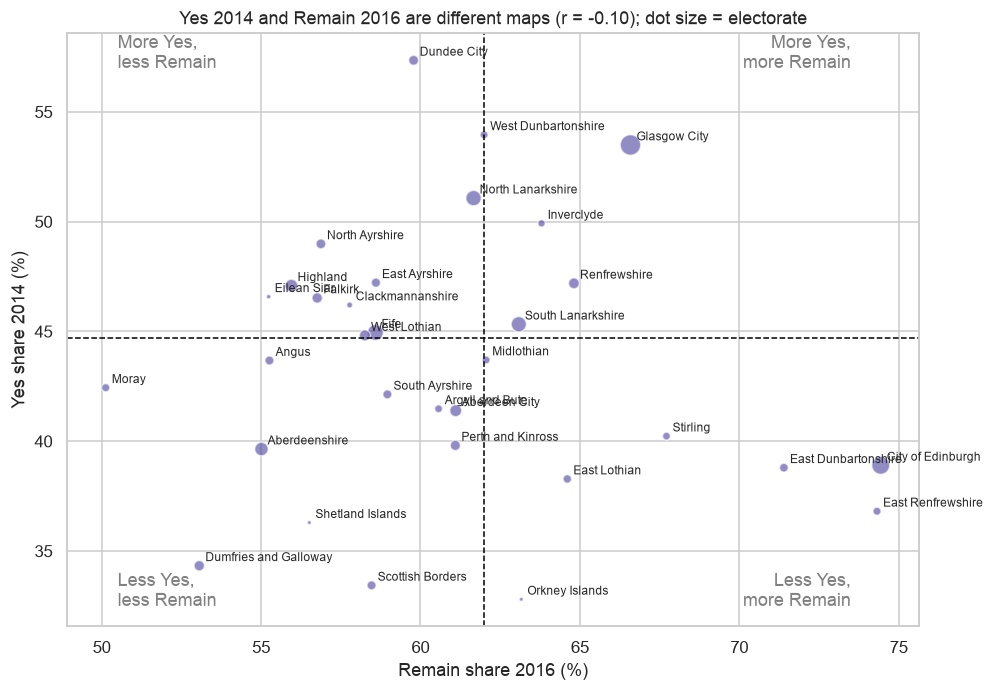

In [18]:
r = stats.pearsonr(sc["remain_pct"], sc["yes_pct"])
ci = r.confidence_interval()
print(f"Remain 2016 vs Yes 2014: r = {r.statistic:.2f}, 95% CI [{ci.low:.2f}, {ci.high:.2f}], p = {r.pvalue:.2f}")

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(sc["remain_pct"], sc["yes_pct"], s=sc["electorate"] / 2500, color=PURPLE, alpha=0.6, edgecolor="white")
ax.axhline(44.7, color="black", linestyle="--", linewidth=1)
ax.axvline(62.0, color="black", linestyle="--", linewidth=1)
for _, row in sc.iterrows():
    ax.annotate(row["area"], (row["remain_pct"], row["yes_pct"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.text(73.5, 57, "More Yes,\nmore Remain", ha="right", color="grey")
ax.text(50.5, 57, "More Yes,\nless Remain", color="grey")
ax.text(73.5, 32.5, "Less Yes,\nmore Remain", ha="right", color="grey")
ax.text(50.5, 32.5, "Less Yes,\nless Remain", color="grey")
ax.set_xlabel("Remain share 2016 (%)")
ax.set_ylabel("Yes share 2014 (%)")
ax.set_title(f"Yes 2014 and Remain 2016 are different maps (r = {r.statistic:.2f}); dot size = electorate")
plt.show()

**What we see**

- **r = -0.10:** no detectable link. Knowing a council's Yes vote tells you almost nothing about its Remain vote.
- **The four corners are all filled:**
  - **More Yes, more Remain:** Glasgow, Renfrewshire, Inverclyde.
  - **Less Yes, more Remain:** Edinburgh, East Renfrewshire, East Dunbartonshire, Stirling. These are wealthy and highly educated councils.
  - **More Yes, less Remain:** Highland, Eilean Siar, North Ayrshire, Falkirk.
  - **Less Yes, less Remain:** Moray, Aberdeenshire, Dumfries and Galloway, the Borders.
- **Dundee** was the strongest Yes council but only middle-ranking for Remain (17th of 32).

### 6.2 How each council's rank changes

A **slope chart** links each council's rank in 2014 (left, by Yes share) with its rank in 2016 (right, by Remain share). If the two votes were the same, the lines would be flat. Crossing lines show councils that moved a lot. We colour the lines by direction: purple goes up the Remain ranking, grey goes down.

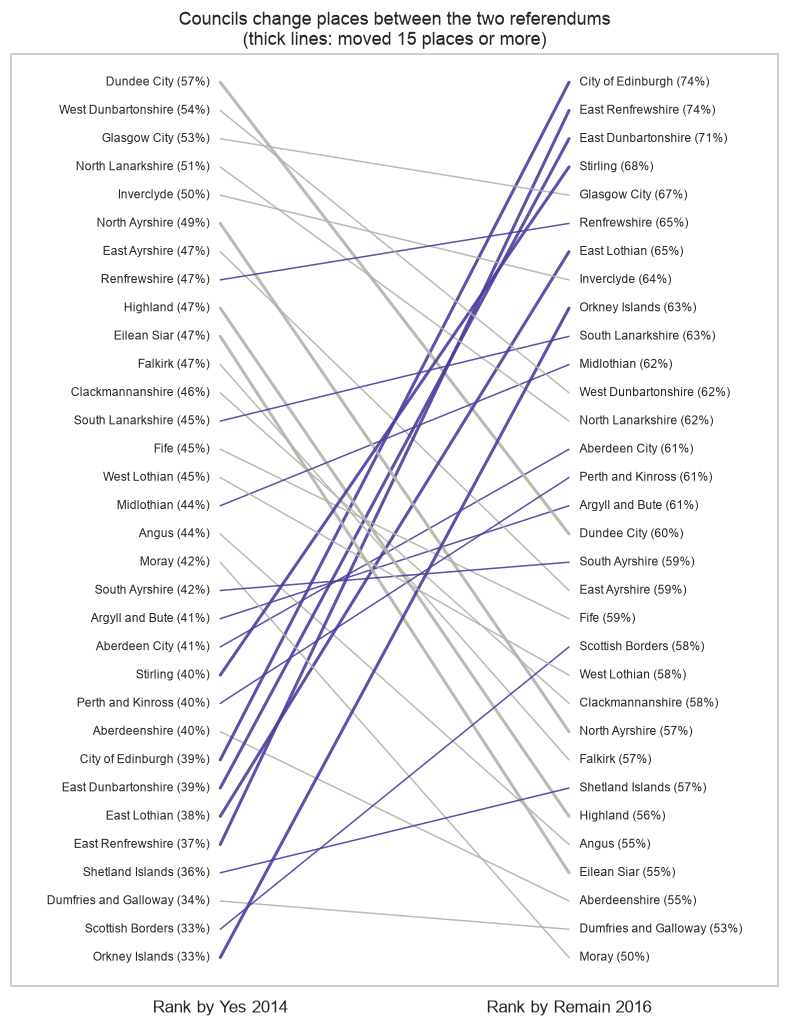

Biggest moves up the Remain ranking:


,area,yes_pct,yes_rank,remain_pct,remain_rank
11,East Renfrewshire,36.8,28,74.3,2
4,City of Edinburgh,38.9,25,74.4,1
9,East Dunbartonshire,38.8,26,71.4,3
22,Orkney Islands,32.8,32,63.2,9
10,East Lothian,38.3,27,64.6,7


Biggest moves down:


,area,yes_pct,yes_rank,remain_pct,remain_rank
12,Eilean Siar,46.6,10,55.2,29
16,Highland,47.1,9,56.0,27
20,North Ayrshire,49.0,6,56.9,24
7,Dundee City,57.3,1,59.8,17
13,Falkirk,46.5,11,56.8,25


Spearman rank correlation: -0.04


In [19]:
fig, ax = plt.subplots(figsize=(9, 11))
for _, row in sc.iterrows():
    up = row["remain_rank"] < row["yes_rank"]
    ax.plot([0, 1], [row["yes_rank"], row["remain_rank"]], color=PURPLE if up else OTHER,
            linewidth=2 if abs(row["remain_rank"] - row["yes_rank"]) >= 15 else 1, alpha=0.9)
    ax.text(-0.03, row["yes_rank"], f'{row["area"]} ({row["yes_pct"]:.0f}%)', ha="right", va="center", fontsize=8)
    ax.text(1.03, row["remain_rank"], f'{row["area"]} ({row["remain_pct"]:.0f}%)', ha="left", va="center", fontsize=8)
ax.set_ylim(33, 0)
ax.set_xlim(-0.6, 1.6)
ax.set_xticks([0, 1], ["Rank by Yes 2014", "Rank by Remain 2016"])
ax.set_yticks([])
ax.grid(False)
ax.set_title("Councils change places between the two referendums\n(thick lines: moved 15 places or more)")
plt.show()

sc["rank_change"] = sc["yes_rank"] - sc["remain_rank"]
print("Biggest moves up the Remain ranking:")
display(sc.nlargest(5, "rank_change")[["area", "yes_pct", "yes_rank", "remain_pct", "remain_rank"]].round(1))
print("Biggest moves down:")
display(sc.nsmallest(5, "rank_change")[["area", "yes_pct", "yes_rank", "remain_pct", "remain_rank"]].round(1))
print("Spearman rank correlation:", round(stats.spearmanr(sc["yes_pct"], sc["remain_pct"]).statistic, 2))

**What we see**

- **The lines cross everywhere.** The rank correlation is close to 0 (Spearman -0.04).
- **Big moves up the Remain ranking:** East Renfrewshire (28th for Yes → 2nd for Remain), Edinburgh (25th → 1st), East Dunbartonshire (26th → 3rd), Orkney (32nd → 9th), East Lothian (27th → 7th) and Stirling (22nd → 4th).
- **Big moves down:** Eilean Siar (10th → 29th), Highland (9th → 27th), North Ayrshire (6th → 24th), Dundee (1st → 17th), Falkirk (11th → 25th) and Moray (18th → 32nd).
- The councils that move up are **wealthy and educated**. The councils that move down are **rural, northern or post-industrial**. The next section tests this.

## 7. What goes with Yes, and what goes with Remain?

**What this cell does:** for each characteristic, it computes two correlations: one with **Yes 2014** and one with **Remain 2016**. Then it puts them side by side.

- **Pearson r** with a **95% confidence interval**. With 32 councils, the intervals are wide, so we read them, not just r.
- **Spearman ρ** as a check against outliers.
- If a characteristic has a strong link with one vote but not the other, the two votes have **different drivers**.

The measures come from two sources: our Scotland table (2016 data) and RP14/50 Table 3.1 (2011-2014 data).

In [20]:
MEASURES = {
    "out_of_work_benefit_pct": "Out-of-work benefits (2014)",
    "claimant_rate": "Claimant rate (2016)",
    "child_poverty_pct": "Child poverty",
    "pct_de": "Social grade DE",
    "pct_degree": "Graduate share",
    "median_weekly_pay": "Median weekly pay",
    "pct_65plus": "Aged 65+",
    "snp_euro_2014_pct": "SNP vote, Euro 2014",
    "scottish_only_identity_pct": "Scottish-only identity",
    "born_in_scotland_pct": "Born in Scotland",
    "ukip_2014_pct": "UKIP vote, Euro 2014",
    "young_voters_pct": "16-17 voters registered",
}

rows = []
for column, label in MEASURES.items():
    for outcome, name in [("yes_pct", "Yes 2014"), ("remain_pct", "Remain 2016")]:
        res = stats.pearsonr(sc[column], sc[outcome])
        ci = res.confidence_interval()
        rows.append({"measure": label, "vote": name, "pearson_r": res.statistic, "ci_low": ci.low, "ci_high": ci.high,
                     "p": res.pvalue, "spearman": stats.spearmanr(sc[column], sc[outcome]).statistic})
links = pd.DataFrame(rows)
display(links.pivot(index="measure", columns="vote", values=["pearson_r", "spearman", "p"]).round(2)
        .loc[list(MEASURES.values())])

pearson_r             spearman           \
vote                        Remain 2016 Yes 2014 Remain 2016 Yes 2014   
measure                                                                 
Out-of-work benefits (2014)        0.02     0.81        0.13     0.79   
Claimant rate (2016)              -0.14     0.85       -0.09     0.86   
Child poverty                      0.04     0.78        0.13     0.79   
Social grade DE                   -0.38     0.67       -0.20     0.73   
Graduate share                     0.59    -0.53        0.33    -0.67   
Median weekly pay                  0.54    -0.39        0.39    -0.35   
Aged 65+                          -0.27    -0.39       -0.22    -0.32   
SNP vote, Euro 2014               -0.35     0.71       -0.44     0.66   
Scottish-only identity            -0.30     0.64       -0.10     0.71   
Born in Scotland                   0.10     0.53        0.20     0.59   
UKIP vote, Euro 2014              -0.70    -0.30       -0.68    -0.21   
16-17 voters registered           -0.06     0.13       -0.11     0.10   

                                      p           
vote                        Remain 2016 Yes 2014  
measure                                           
Out-of-work benefits (2014)        0.93     0.00  
Claimant rate (2016)               0.45     0.00  
Child poverty                      0.83     0.00  
Social grade DE                    0.03     0.00  
Graduate share                     0.00     0.00  
Median weekly pay                  0.00     0.03  
Aged 65+                           0.14     0.03  
SNP vote, Euro 2014                0.05     0.00  
Scottish-only identity             0.10     0.00  
Born in Scotland                   0.60     0.00  
UKIP vote, Euro 2014               0.00     0.10  
16-17 voters registered            0.75     0.48

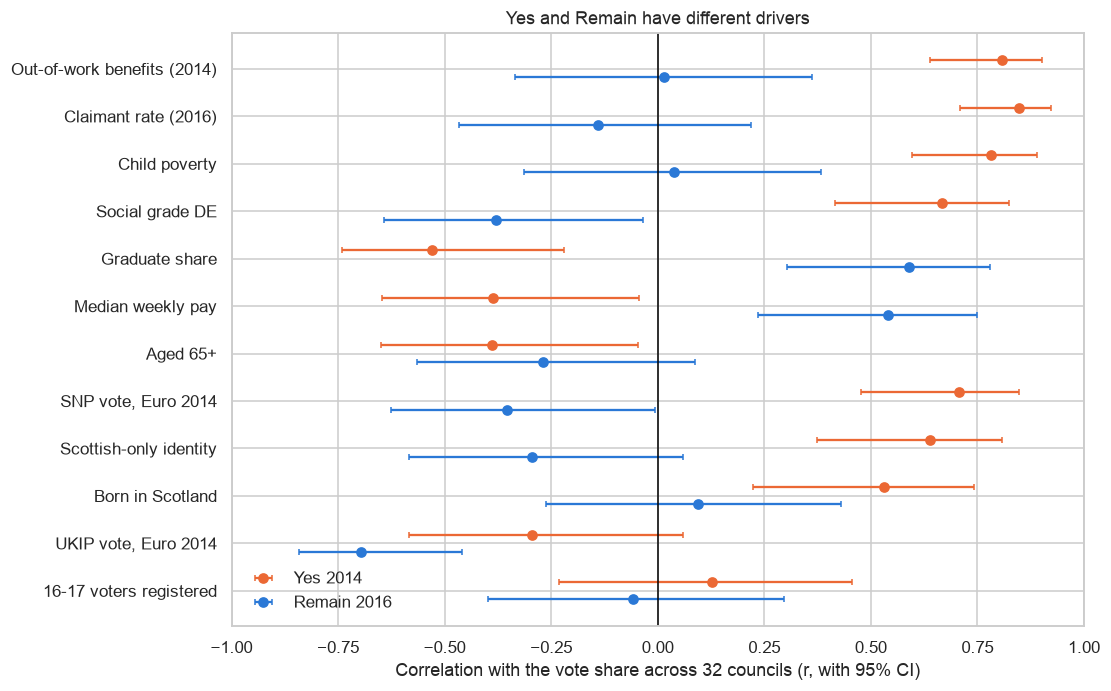

In [21]:
fig, ax = plt.subplots(figsize=(10, 7))
order = list(MEASURES.values())[::-1]
y = np.arange(len(order))
for offset, (vote, colour) in zip([0.18, -0.18], [("Yes 2014", LONDON), ("Remain 2016", SCOTLAND)]):
    d = links[links["vote"] == vote].set_index("measure").loc[order]
    ax.errorbar(d["pearson_r"], y + offset, xerr=[d["pearson_r"] - d["ci_low"], d["ci_high"] - d["pearson_r"]],
                fmt="o", color=colour, label=vote, capsize=2)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y, order)
ax.set_xlim(-1, 1)
ax.set_xlabel("Correlation with the vote share across 32 councils (r, with 95% CI)")
ax.set_title("Yes and Remain have different drivers")
ax.legend(frameon=False, loc="lower left")
plt.show()

**What we see: two different logics**

**Yes 2014 follows deprivation and the SNP**
- Out-of-work benefits **r = 0.81**, claimant rate **0.85**, child poverty **0.78**, social grade DE **0.67**.
- SNP Euro 2014 **0.71**, Scottish-only identity **0.64**, born in Scotland **0.53**.
- Fewer graduates (-0.53), lower pay (-0.39) and younger populations (65+: -0.39) also go with Yes.

**Remain 2016 follows education and the absence of UKIP**
- Graduate share **r = 0.59** and median pay **0.54**: the same pattern as across Great Britain, where graduates are the strongest predictor of Remain.
- UKIP Euro 2014 **-0.70**: the strongest link. Where UKIP did better in 2014, Remain was weaker (Moray, Dumfries and Galloway, Aberdeenshire).
- **Deprivation has no link with Remain** (benefits 0.02, child poverty 0.04).
- **National identity doesn't push towards Remain.** SNP Euro 2014 (-0.35) and Scottish-only identity (-0.30) lean slightly the *other* way. Councils with more nationalists were, if anything, a little *less* Remain. The intervals are wide, so read this as "no sign of a nationalist Remain vote", not as a strong opposite effect.

**Careful with the graduate link:** Spearman for Remain is only 0.33, against Pearson 0.59 (see notebook 02). Edinburgh and the two wealthy suburbs pull the Pearson value up.

**16-17-year-old registration** has no link with either vote, so it can't explain the 2014 pattern at council level.

### 7.1 Side by side: four key measures

**What this cell does:** for four measures (one from each group: deprivation, nationalism, education, UKIP), it draws the Yes scatter (top row, orange) and the Remain scatter (bottom row, blue), each with its trend line and r. Five councils are named so you can follow them across the charts.

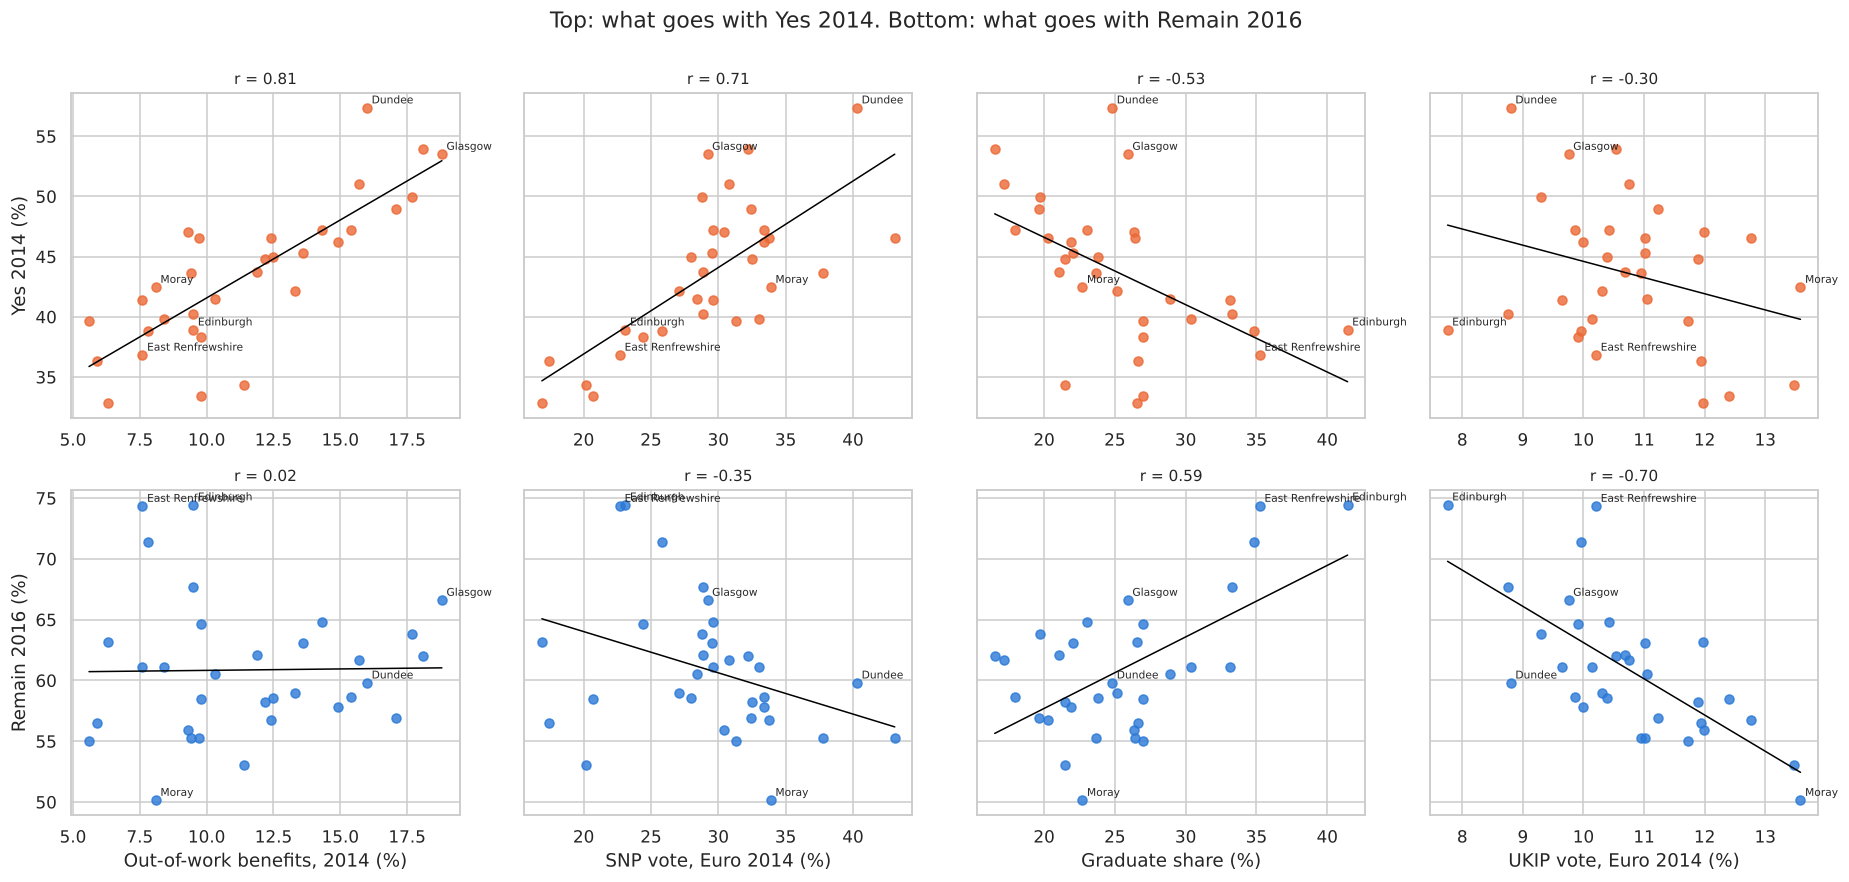

In [11]:
KEY4 = [("out_of_work_benefit_pct", "Out-of-work benefits, 2014 (%)"), ("snp_euro_2014_pct", "SNP vote, Euro 2014 (%)"),
        ("pct_degree", "Graduate share (%)"), ("ukip_2014_pct", "UKIP vote, Euro 2014 (%)")]
NAMED = ["Glasgow City", "City of Edinburgh", "Dundee City", "Moray", "East Renfrewshire"]

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharey="row")
for row, (outcome, label, colour) in enumerate([("yes_pct", "Yes 2014 (%)", LONDON), ("remain_pct", "Remain 2016 (%)", SCOTLAND)]):
    for col, (column, xlabel) in enumerate(KEY4):
        ax = axes[row, col]
        ax.scatter(sc[column], sc[outcome], color=colour, s=35, alpha=0.8)
        slope, intercept = np.polyfit(sc[column], sc[outcome], 1)
        xs = np.linspace(sc[column].min(), sc[column].max(), 50)
        ax.plot(xs, intercept + slope * xs, color="black", linewidth=1)
        r = stats.pearsonr(sc[column], sc[outcome]).statistic
        ax.set_title(f"r = {r:.2f}", fontsize=10)
        for name in NAMED:
            p = sc[sc["area"] == name].iloc[0]
            ax.annotate(name.replace("City of ", "").replace(" City", ""), (p[column], p[outcome]),
                        xytext=(3, 3), textcoords="offset points", fontsize=7)
        ax.set_xlabel(xlabel if row == 1 else "")
        if col == 0:
            ax.set_ylabel(label)
fig.suptitle("Top: what goes with Yes 2014. Bottom: what goes with Remain 2016", y=1.0)
plt.tight_layout()
plt.show()

**What we see**

- **Out-of-work benefits:** a steep line for Yes (Glasgow and Dundee at the top right) and a flat line for Remain.
- **SNP 2014:** rising for Yes, slightly falling for Remain.
- **Graduates:** falling for Yes, rising for Remain. Edinburgh and East Renfrewshire sit high on Remain and low on Yes.
- **UKIP 2014:** the clearest Remain pattern. **Moray** has the highest UKIP share (13.6%) and the lowest Remain share (50.1%).

So the two referendums drew on **different divides**: 2014 split Scotland by **deprivation and national identity**, 2016 split it (much more mildly) by **education and Euroscepticism**, the same divide as in England, but around a much higher Remain level.

## 8. Turnout: where did 2014 voters stay at home in 2016?

**What this cell does**

1. It maps turnout in 2014, turnout in 2016 and the **drop** between them, with a purple scale (darker = higher).
2. It plots the drop against the Yes share, with the correlation.

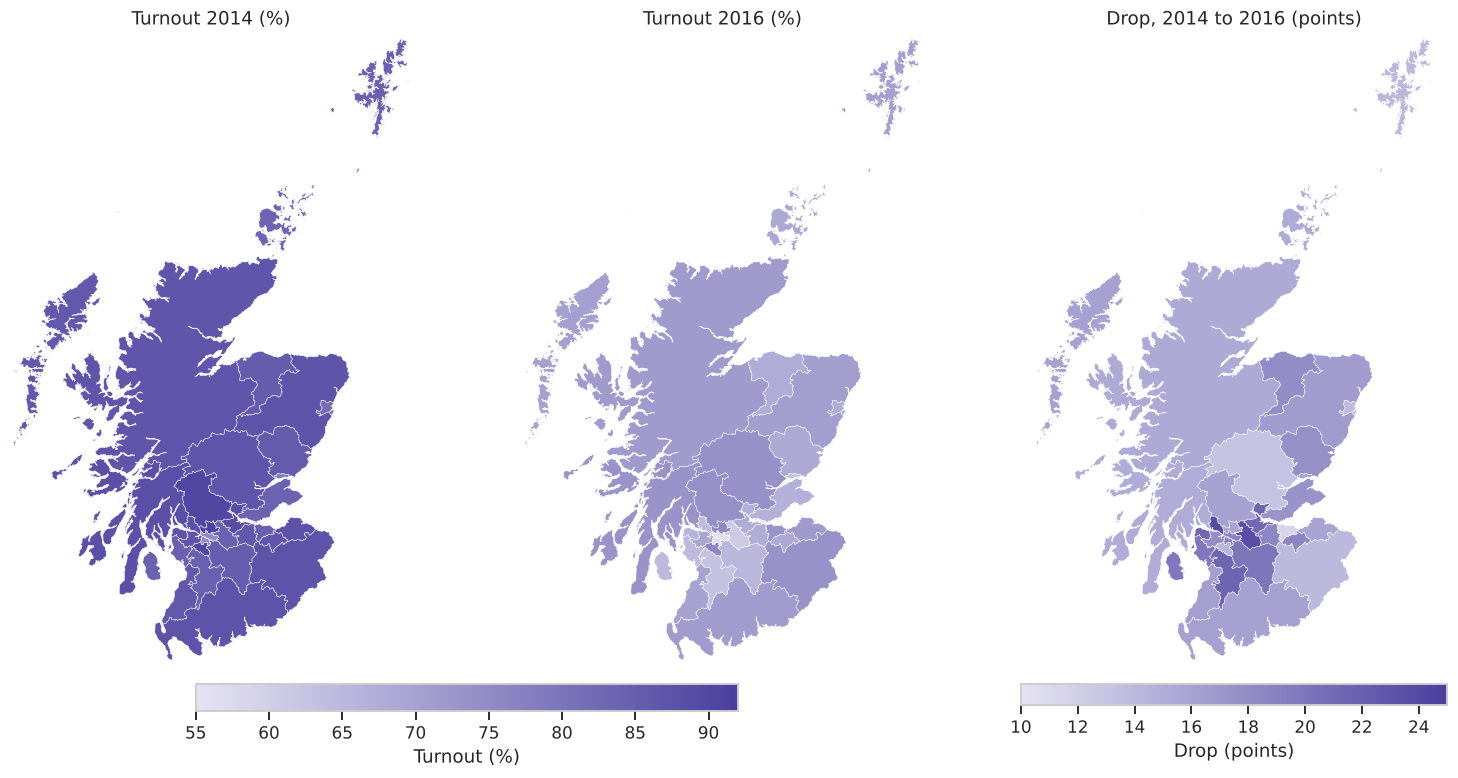

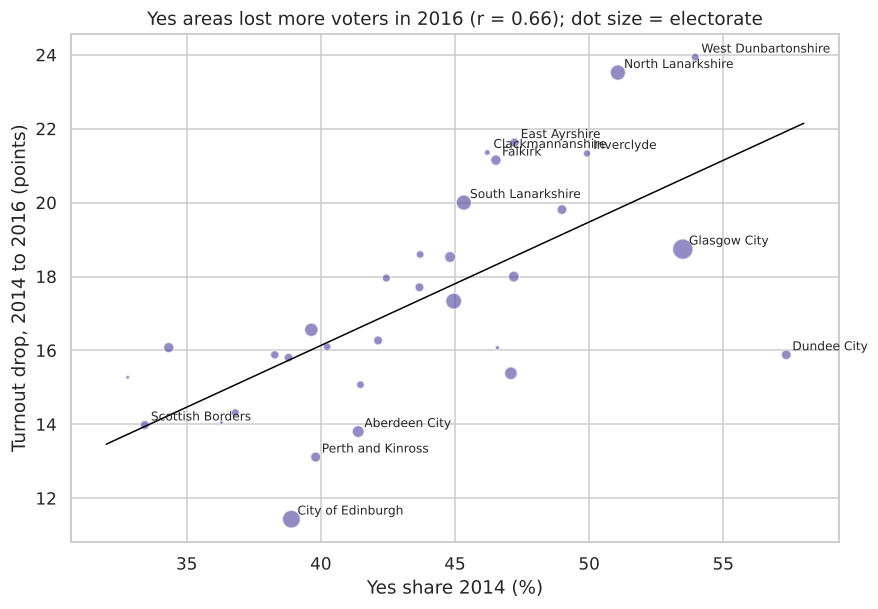

Turnout drop vs Yes 2014:    r = 0.66, 95% CI [0.40, 0.82], p = 4.2e-05
Turnout drop vs Remain 2016: r = -0.22, p = 0.23


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 8))
turnout_scale = Normalize(vmin=55, vmax=92)
l1 = draw_scotland(axes[0], sc.set_index("code")["turnout_2014_pct"], cmap=purple_colours, norm=turnout_scale)
draw_scotland(axes[1], sc.set_index("code")["turnout_pct"], cmap=purple_colours, norm=turnout_scale)
l3 = draw_scotland(axes[2], sc.set_index("code")["turnout_drop"], cmap=purple_colours, norm=Normalize(vmin=10, vmax=25))
axes[0].set_title("Turnout 2014 (%)")
axes[1].set_title("Turnout 2016 (%)")
axes[2].set_title("Drop, 2014 to 2016 (points)")
fig.colorbar(l1, ax=axes[:2], orientation="horizontal", fraction=0.04, pad=0.03, label="Turnout (%)")
fig.colorbar(l3, ax=axes[2], orientation="horizontal", fraction=0.04, pad=0.03, label="Drop (points)")
plt.show()

r = stats.pearsonr(sc["yes_pct"], sc["turnout_drop"])
ci = r.confidence_interval()
print(f"Turnout drop vs Yes 2014:    r = {r.statistic:.2f}, 95% CI [{ci.low:.2f}, {ci.high:.2f}], p = {r.pvalue:.1e}")
r2 = stats.pearsonr(sc["remain_pct"], sc["turnout_drop"])
print(f"Turnout drop vs Remain 2016: r = {r2.statistic:.2f}, p = {r2.pvalue:.2f}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(sc["yes_pct"], sc["turnout_drop"], s=sc["electorate"] / 2500, color=PURPLE, alpha=0.6, edgecolor="white")
for _, row in sc.iterrows():
    if row["turnout_drop"] > 20 or row["turnout_drop"] < 14 or row["yes_pct"] > 52:
        ax.annotate(row["area"], (row["yes_pct"], row["turnout_drop"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
slope, intercept = np.polyfit(sc["yes_pct"], sc["turnout_drop"], 1)
xs = np.linspace(32, 58, 50)
ax.plot(xs, intercept + slope * xs, color="black", linewidth=1)
ax.set_xlabel("Yes share 2014 (%)")
ax.set_ylabel("Turnout drop, 2014 to 2016 (points)")
ax.set_title(f"Yes areas lost more voters in 2016 (r = {r.statistic:.2f}); dot size = electorate")
plt.show()

**What we see**

- **2014 turnout was very high everywhere** (75% to 91%). The highest was in wealthy suburbs (East Dunbartonshire 91.0%, East Renfrewshire 90.4%) and the lowest in Glasgow (75.0%) and Dundee (78.8%).
- **2016 turnout fell everywhere**, by **17 points on average**, from 11 points in Edinburgh to 24 in West Dunbartonshire and North Lanarkshire.
- **The drop was largest in the Yes councils (r = 0.66, p < 0.001).** About 3 extra points of drop for every 10 points of Yes.
- The drop has **no clear link with Remain** (r = -0.22, p = 0.23).

**Why it matters:** the 2014 referendum mobilised people in deprived, pro-independence areas who didn't come back in 2016. So the 2016 vote in Scotland was cast by an **older, better-off and more educated electorate** than in 2014. This is a council-level pattern: it doesn't prove which individuals stayed home.

## 9. Inside the two big cities

Results were officially declared only by council, but Glasgow and Edinburgh councils published breakdowns (RP14/50 Table 4). Glasgow is split by **Scottish Parliament** constituency, Edinburgh by **UK Parliament** constituency, so they're not the same kind of unit.

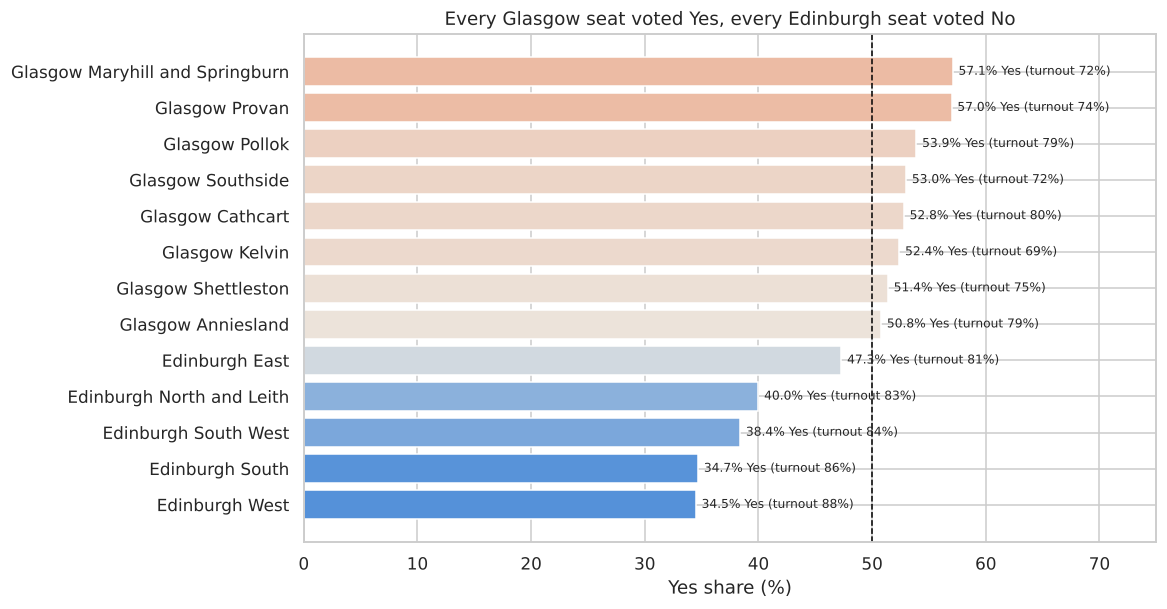

Yes vs turnout across these 13 seats: r = -0.85


In [13]:
# Source: House of Commons Library RP14/50, Table 4 (2014 referendum)
cities = pd.DataFrame([
    ("Glasgow", "Anniesland", 50.8, 79.2), ("Glasgow", "Cathcart", 52.8, 80.0), ("Glasgow", "Kelvin", 52.4, 68.8),
    ("Glasgow", "Maryhill and Springburn", 57.1, 72.5), ("Glasgow", "Pollok", 53.9, 78.7),
    ("Glasgow", "Provan", 57.0, 74.0), ("Glasgow", "Shettleston", 51.4, 75.1), ("Glasgow", "Southside", 53.0, 71.6),
    ("Edinburgh", "East", 47.3, 80.7), ("Edinburgh", "North and Leith", 40.0, 83.2), ("Edinburgh", "South", 34.7, 85.7),
    ("Edinburgh", "South West", 38.4, 84.1), ("Edinburgh", "West", 34.5, 88.5)],
    columns=["city", "constituency", "yes_pct", "turnout_pct"]).sort_values(["city", "yes_pct"])

fig, ax = plt.subplots(figsize=(10, 6))
labels = cities["city"] + " " + cities["constituency"]
ax.barh(labels, cities["yes_pct"], color=vote_colours(vote_scale(cities["yes_pct"])))
for i, (v, t) in enumerate(zip(cities["yes_pct"], cities["turnout_pct"])):
    ax.text(v + 0.5, i, f"{v:.1f}% Yes (turnout {t:.0f}%)", va="center", fontsize=8)
ax.axvline(50, color="black", linestyle="--", linewidth=1)
ax.set_xlim(0, 75)
ax.set_xlabel("Yes share (%)")
ax.set_title("Every Glasgow seat voted Yes, every Edinburgh seat voted No")
plt.show()

r = stats.pearsonr(cities["yes_pct"], cities["turnout_pct"])
print(f"Yes vs turnout across these 13 seats: r = {r.statistic:.2f}")

**What we see**

- **All 8 Glasgow seats voted Yes**, from 50.8% (Anniesland) to 57.1% (Maryhill and Springburn). Provan, one of the most deprived areas in Scotland, gave 57.0%.
- **All 5 Edinburgh seats voted No.** Edinburgh East came closest (47.3% Yes). Edinburgh West and South were the most No (about 65%).
- **Within the cities, higher Yes goes with lower turnout** (r = -0.85 across the 13 seats). Notebook 01's council-level pattern repeats inside the cities.

## 10. Who voted Yes? Polling-day surveys

So far everything is about **places**. Two surveys on polling day asked **individuals** how they voted (RP14/50 Table 6.1). This shows whether the council patterns match individual behaviour.

**Be careful:** these are samples of about 2,000-2,700 people, with a margin of error of about ±2-3 points overall, and more for small groups. The age groups differ between the two pollsters.

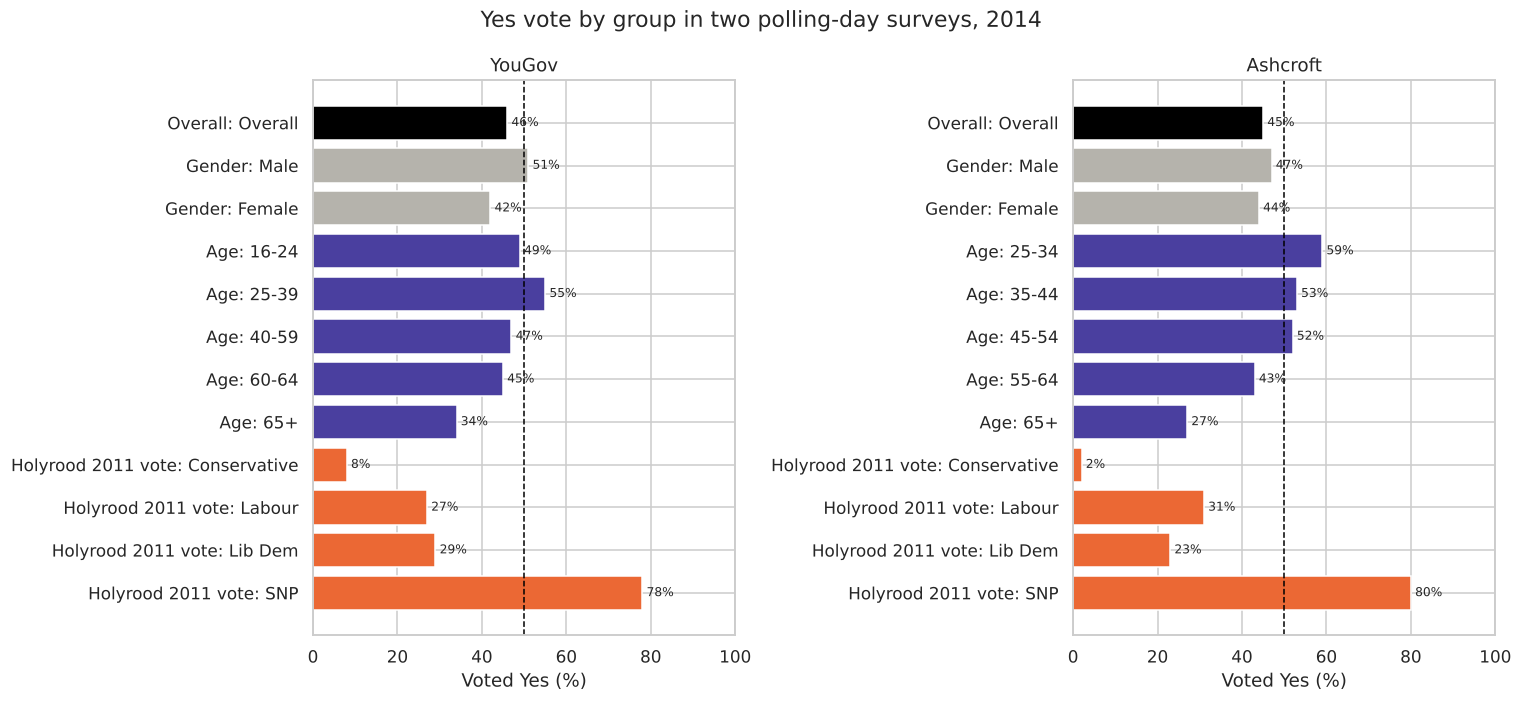

In [14]:
# Source: RP14/50 Table 6.1. YouGov (fieldwork 15-18 Sep 2014) and Lord Ashcroft Polls (18-19 Sep 2014). Yes %.
surveys = pd.DataFrame([
    ("YouGov", "Overall", "Overall", 46), ("YouGov", "Gender", "Male", 51), ("YouGov", "Gender", "Female", 42),
    ("YouGov", "Age", "16-24", 49), ("YouGov", "Age", "25-39", 55), ("YouGov", "Age", "40-59", 47),
    ("YouGov", "Age", "60-64", 45), ("YouGov", "Age", "65+", 34),
    ("YouGov", "Holyrood 2011 vote", "Conservative", 8), ("YouGov", "Holyrood 2011 vote", "Labour", 27),
    ("YouGov", "Holyrood 2011 vote", "Lib Dem", 29), ("YouGov", "Holyrood 2011 vote", "SNP", 78),
    ("Ashcroft", "Overall", "Overall", 45), ("Ashcroft", "Gender", "Male", 47), ("Ashcroft", "Gender", "Female", 44),
    ("Ashcroft", "Age", "25-34", 59), ("Ashcroft", "Age", "35-44", 53), ("Ashcroft", "Age", "45-54", 52),
    ("Ashcroft", "Age", "55-64", 43), ("Ashcroft", "Age", "65+", 27),
    ("Ashcroft", "Holyrood 2011 vote", "Conservative", 2), ("Ashcroft", "Holyrood 2011 vote", "Labour", 31),
    ("Ashcroft", "Holyrood 2011 vote", "Lib Dem", 23), ("Ashcroft", "Holyrood 2011 vote", "SNP", 80)],
    columns=["pollster", "group", "category", "yes_pct"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True)
group_colours = {"Overall": "black", "Gender": OTHER, "Age": PURPLE, "Holyrood 2011 vote": LONDON}
for ax, pollster in zip(axes, ["YouGov", "Ashcroft"]):
    d = surveys[surveys["pollster"] == pollster].iloc[::-1]
    ax.barh(d["group"] + ": " + d["category"], d["yes_pct"], color=d["group"].map(group_colours))
    for i, v in enumerate(d["yes_pct"]):
        ax.text(v + 1, i, f"{v}%", va="center", fontsize=8)
    ax.axvline(50, color="black", linestyle="--", linewidth=1)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Voted Yes (%)")
    ax.set_title(pollster)
fig.suptitle("Yes vote by group in two polling-day surveys, 2014")
plt.tight_layout()
plt.show()

**What we see**

- **Age is the biggest divide:** only **27-34% of over-65s** voted Yes, against **55-59% of people aged 25-39**. This matches the weak negative link between the 65+ share and Yes across councils.
- **Gender:** men leaned more Yes than women (51% vs 42% in YouGov; 47% vs 44% in Ashcroft).
- **Party:** about **4 in 5 SNP voters** voted Yes, so about 1 in 5 voted No. **A quarter to a third of Labour voters** voted Yes, which helps explain the Yes vote in Labour's west-central heartlands (Glasgow, Lanarkshire, Dunbartonshire).
- RP14/50 also reports that **late deciders leaned Yes (62%)**, that Yes voters' top issues were Westminster and the NHS, and No voters' top issues were the pound and pensions.

**Link to the project:** the same individuals who lean Yes (younger, working-age, Labour heartlands) are spread across councils that voted Remain at very different levels. That's consistent with r ≈ 0 between the two votes.

## 11. Main findings

| # | Finding | Evidence |
|---|---|---|
| 1 | Yes 2014 won 44.7% and 4 councils, all in the west-central belt plus Dundee | Map, section 4 |
| 2 | Every council voted Remain in 2016, and Remain got more votes than Yes | Sections 3 and 5 |
| 3 | **The Yes map and the Remain map are different maps** | r = -0.10, Spearman -0.04; councils cross ranks everywhere |
| 4 | **Yes follows deprivation and the SNP** | Benefits r = 0.81, claimant 0.85, SNP 2014 0.71, Scottish-only identity 0.64 |
| 5 | **Remain follows education and low UKIP**, like in England | UKIP 2014 r = -0.70, graduates 0.59 (Spearman 0.33), pay 0.54 |
| 6 | **No sign of a nationalist Remain vote** at council level | SNP 2014 vs Remain r = -0.35, Scottish-only identity -0.30 |
| 7 | **Turnout fell most in Yes areas** between 2014 and 2016 | r = 0.66 between Yes share and turnout drop |
| 8 | Within cities and among individuals, the same patterns appear | Glasgow all Yes, Edinburgh all No; over-65s 27-34% Yes |

**What this means for Part 2 (the model)**

- Scotland's high Remain vote **isn't explained by deprivation or nationalism**, and its internal pattern looks like England's (education, UKIP). So Scotland seems to share the **same drivers at a different level**: a **level shift**, which a Scotland term in the model captures (model C in notebook 02: -15.5 points).
- The 2016 electorate in Scotland was **less mobilised in deprived areas** than in 2014, which should be mentioned when comparing the two votes.
- Possible extra features for a Scotland-only analysis: SNP Euro 2014 share, Scottish-only identity, and turnout drop. With 32 councils, use them for description, not for a predictive model.

**Scope reminders:** results describe councils, not voters. This notebook describes the past and is not a forecast of any future referendum.

## 12. The whole notebook in simple words

1. **The two votes:** in 2014 Scotland voted No to independence (55.3%). In 2016 it voted Remain (62.0%), and every council voted Remain.
2. **The Yes map:** Yes won in Glasgow, Dundee, West Dunbartonshire and North Lanarkshire. The strongest No areas were the islands and the councils bordering England.
3. **Two different maps:** the councils that voted most Yes aren't the councils that voted most Remain. Edinburgh was one of the most No councils and the most Remain. Dundee was the most Yes but only middle for Remain.
4. **Different reasons:** Yes was strongest where more people were out of work and where the SNP was strong. Remain was strongest where more people had degrees and where UKIP was weak. That's the same pattern as in England.
5. **Not a nationalist Remain:** councils with more nationalists weren't more Remain, if anything slightly less.
6. **Turnout:** many people who voted in 2014 didn't vote in 2016, especially in the Yes areas.
7. **Inside the cities and among voters:** all of Glasgow voted Yes and all of Edinburgh voted No. Younger people and Labour voters in the west leaned Yes, older people leaned No.

**Sources:** referendum results from the Electoral Commission (2016) and House of Commons Library Research Paper 14/50 (2014), which also provides Table 3.1, Table 4 and Table 6.1. Boundaries: Ordnance Survey and ONS data © Crown copyright 2014, via UK-GeoJSON by Martin Chorley (CC BY 4.0).